# 7. Checking the references by hand

Two native-speaker annotators, blind to the system, verified 605 reference transcripts, labeled word pairs (same word in
another spelling, dialect form, or a different word) and audited every difference between the zero-shot model and the
reference. A third party settled their disagreements by choosing one of the two answers.

In [1]:
from nbutil import *
import pandas as pd
s = load('results/labels/summary.json')

## Agreement between the annotators

In [2]:
pd.DataFrame({
    "verified references": {"double-labeled": s["refs"]["agreement"]["double_labeled"], "agreement": f"{100 * s['refs']['agreement']['status_agreement']:.1f}% same status"},
    "word pairs": {"double-labeled": s["pairs"]["agreement"]["pairs"], "agreement": f"Cohen's kappa {s['pairs']['agreement']['fleiss_kappa']:.2f}"},
    "error audit": {"double-labeled": s["audit"]["cohen_kappa"]["units"], "agreement": f"Cohen's kappa {s['audit']['cohen_kappa']['kappa']:.2f}"},
}).T

,double-labeled,agreement
verified references,64,73.4% same status
word pairs,150,Cohen's kappa 0.71
error audit,370,Cohen's kappa 0.56


In [3]:
adj = load("results/labels/adjudication.json")
pd.Series([r["task"] for r in adj["resolutions"]]).value_counts().rename("disagreements settled")

audit    44
ref      30
pair     29
Name: disagreements settled, dtype: int64

## Reference noise: share of reference words the annotators changed

In [4]:
pd.DataFrame({src: {"clips": e["chunks"], "clips corrected %": round(100 * e["corrected_share"], 1),
                    "words changed %": round(100 * e["edit_rate"]["value"], 2),
                    "95% CI": f"[{100 * e['edit_rate']['ci95'][0]:.2f}, {100 * e['edit_rate']['ci95'][1]:.2f}]"}
              for src, e in s["refs"]["by_source"].items()}).T

,clips,clips corrected %,words changed %,95% CI
commonvoice,100,14.0,1.84,"[0.93, 3.13]"
dlsprint,305,30.2,1.88,"[1.34, 2.46]"
fleurs,100,46.0,4.4,"[3.23, 5.89]"
kathbath,100,9.0,1.19,"[0.40, 2.03]"


In [5]:
pd.read_csv(ROOT / "results/labels/noise_by_alignment.csv").round(4)

,tercile,score_min,score_max,clips,corrected_share,edit_rate,ci_low,ci_high
0,low,0.5060,0.8496,102,0.3922,0.0280,0.0187,0.0365
1,mid,0.8517,0.9057,101,0.3663,0.0198,0.0125,0.0300
2,high,0.9064,0.9676,102,0.1471,0.0079,0.0041,0.0129


## What the differences are (zero-shot model, DL Sprint eval)

In [6]:
a = s["audit"]
pd.DataFrame({g: {k: round(100 * v["value"], 1) for k, v in a["shares_by_agreement"][g].items()}
              for g in ("selection_proof", "fixable")}).rename(columns={"selection_proof": "no candidate has the word", "fixable": "some candidate has it"})

,no candidate has the word,some candidate has it
model,37.2,42.3
ref,21.5,10.6
both,1.0,0.2
spelling,35.6,40.2
dialect,1.6,4.9
unsure,3.2,1.7


## Every model against the verified references

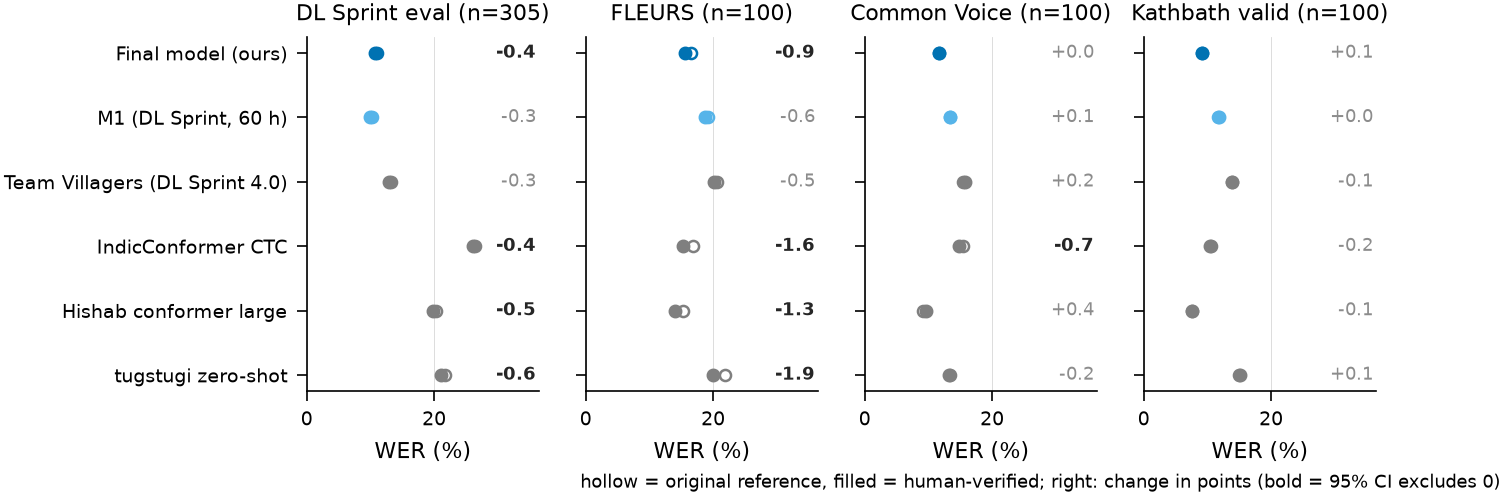

,set,system,utts,wer_original,wer_verified,diff,diff_lo,diff_hi
0,DL Sprint eval,tugstugi zero-shot,305,21.63,21.00,-0.63,-1.03,-0.30
1,DL Sprint eval,Hishab conformer large,305,20.35,19.80,-0.55,-0.81,-0.29
2,DL Sprint eval,IndicConformer CTC,305,26.48,26.08,-0.40,-0.72,-0.11
3,DL Sprint eval,Team Villagers (DL Sprint 4.0),305,13.15,12.85,-0.30,-0.75,0.14
4,DL Sprint eval,"M1 (DL Sprint, 60 h)",305,10.23,9.89,-0.34,-0.74,0.06
5,DL Sprint eval,Final model (ours),305,11.07,10.65,-0.42,-0.76,-0.07
6,FLEURS,tugstugi zero-shot,100,21.93,20.02,-1.91,-2.85,-1.03
7,FLEURS,Hishab conformer large,100,15.31,14.05,-1.26,-2.07,-0.50
8,FLEURS,IndicConformer CTC,100,16.83,15.25,-1.57,-2.47,-0.75
9,FLEURS,Team Villagers (DL Sprint 4.0),100,20.67,20.12,-0.55,-1.43,0.34


In [7]:
figure("f17_verified_references"); figure_data("f17_verified_references").round(2)

In [8]:
pd.read_csv(ROOT / "results/labels/adjudication_sensitivity.csv").round(4)

,set,system,settled_clips,wer_adjudicated,wer_other_answer,difference
0,dlsprint,final model,16,0.1065,0.1067,-0.0002
1,dlsprint,tugstugi zero-shot,16,0.2100,0.2115,-0.0015
2,dlsprint,Hishab conformer large,16,0.1980,0.2000,-0.0019
3,dlsprint,IndicConformer CTC,16,0.2608,0.2618,-0.0010
4,fleurs,final model,8,0.1560,0.1582,-0.0022
5,fleurs,tugstugi zero-shot,8,0.2002,0.2039,-0.0037
6,fleurs,Hishab conformer large,8,0.1405,0.1452,-0.0047
7,fleurs,IndicConformer CTC,8,0.1525,0.1572,-0.0047
8,kathbath,final model,4,0.0917,0.0954,-0.0037
9,kathbath,tugstugi zero-shot,4,0.1505,0.1541,-0.0037


**Next:** about a third of the differences are only spelling. Notebook 8 scores every model without counting them.